# INSY 674 Final Project — Part 2: Explore the Data
**Owner:** Hasan Malik · **Section:** Data exploration and profiling

**Research question.** Using only information available when an order is approved, how accurately can we predict the risk of late delivery, and which factors contribute most to that risk?

**Target.** `is_late` = 1 when the order reached the customer on a calendar day *after* the delivery date Olist promised at checkout. We model **P(late | information at approval)**.

**What this notebook delivers** (Géron, Appendix B — *Explore the Data*):

| Checklist item | Section |
|---|---|
| Create a copy of the data for exploration | §1 |
| Identify the target | §2 |
| Study each attribute (type, % missing, noise, distribution, usefulness) | §3–§4 (profiling table) |
| Visualize the data | §5–§7 |
| Study correlations | §8 |
| Promising transformations | §9 |
| Extra data that would help | §10 |
| Document what we learned | §11 |

Outputs written to disk for the team: `outputs/profiling_table.csv`, `outputs/data_quality_issues.csv`, `outputs/split_ids.csv`, and every figure in `figures/`.

In [ ]:

# olist_merged_modeling.csv is optional; it is only used in §0 to justify the file choice.
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_PATH = "olist_final.csv"
UNFILTERED_PATH = "olist_merged_modeling.csv"   
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# ---- Plot style: one consistent, colorblind-safe palette ----------------
ON_TIME, LATE = "#2a78d6", "#eb6834"          # blue = on time, orange = late (used everywhere)
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#9ec5f4", "#f0efec", "#f1a2a1", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})
pct = mtick.PercentFormatter(1.0, decimals=0)
plain_log = mtick.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}")

def tidy_log_axis(ax):
    ax.xaxis.set_major_formatter(plain_log)
    ax.xaxis.set_minor_formatter(mtick.NullFormatter())

def save(fig, name):
    fig.savefig(f"figures/{name}.png")
    plt.show()

## 0. Which file, and why `olist_final.csv`

The team produced two merged files with identical columns. `olist_merged_modeling.csv` (96,456 delivered orders) is the raw merge; `olist_final.csv` (85,371) removes two slices. The check below shows what was removed and why it matters.

In [2]:
ts_cols = ["order_purchase_timestamp", "order_approved_at",
           "order_delivered_customer_date", "order_estimated_delivery_date"]
df = pd.read_csv(DATA_PATH, parse_dates=ts_cols)
print(f"olist_final: {df.shape[0]:,} orders x {df.shape[1]} columns")

if os.path.exists(UNFILTERED_PATH):
    raw = pd.read_csv(UNFILTERED_PATH, parse_dates=ts_cols)
    dropped = raw[~raw.order_id.isin(df.order_id)]
    kept_purchase_min = df.order_purchase_timestamp.min()
    early = dropped[dropped.order_purchase_timestamp < kept_purchase_min]
    tail = dropped[dropped.order_purchase_timestamp >= kept_purchase_min]
    summary = pd.DataFrame({
        "orders": [len(raw), len(df), len(early), len(tail)],
        "late rate": [raw.is_late.mean(), df.is_late.mean(), early.is_late.mean(), tail.is_late.mean()],
    }, index=["unfiltered merge", "olist_final (kept)", "dropped: 2016 orders",
              "dropped: promise date after 2018-08-01"])
    print(f"Max promised date kept in olist_final: {df.order_estimated_delivery_date.max().date()}")
    display(summary.style.format({"orders": "{:,}", "late rate": "{:.1%}"}))

olist_final: 85,371 orders x 29 columns


Max promised date kept in olist_final: 2018-08-01


,orders,late rate
unfiltered merge,"96,456",6.8%
olist_final (kept),"85,371",7.0%
dropped: 2016 orders,267,1.1%
dropped: promise date after 2018-08-01,"10,818",5.0%


**Takeaway — why we use `olist_final.csv`.**
* **2016 orders (267, late rate 1.1%)** come from the platform's sparse launch months (Sep–Dec 2016). Too few to learn from, and not representative of normal operations.
* **Orders promised after 1 Aug 2018 (10,818)** sit at the very end of the data pull. Only *delivered* orders are in either file, so for orders near the cut-off, deliveries that were running late may simply not have arrived yet and are missing. This is **right-censoring**, and it would bias the label toward "on time". Cutting on the promise date guards against it.
* Net effect: 85,371 orders, **late rate 7.0%** (vs 6.8% in the unfiltered merge). *Note for the slides:* the "~8% / ~7,800 late orders" quoted in the group chat comes from the raw Kaggle data with a timestamp rule. Our modelling file has **5,986 late orders (7.0%)**.

## 1. Create the exploration copy (and lock the test set away first)

Géron's checklist says to explore a *copy* of the data. We go one step further and split **before** looking at anything, so that nothing we learn here (bins, outlier thresholds, category groupings, target encodings) is influenced by the test set. That keeps the downstream pipeline leak-free, which the rubric's *Prepare the Data* band requires.

* **Split:** stratified 80/20 on `is_late`, `random_state=42`. Stratifying keeps the ~7% late share identical in both halves.
* **Saved to** `outputs/split_ids.csv` so every teammate trains and tests on the same orders.
* All statistics and plots below use **`train` only**.

In [3]:
train_ids, test_ids = train_test_split(df.order_id, test_size=0.20, stratify=df.is_late,
                                       random_state=RANDOM_STATE)
split = pd.concat([pd.DataFrame({"order_id": train_ids, "split": "train"}),
                   pd.DataFrame({"order_id": test_ids, "split": "test"})])
split.to_csv("outputs/split_ids.csv", index=False)

train = df[df.order_id.isin(train_ids)].copy()     # exploration copy
print(f"train: {len(train):,} orders (late rate {train.is_late.mean():.2%})")
print(f"test : {len(test_ids):,} orders (late rate {df[df.order_id.isin(test_ids)].is_late.mean():.2%}) — not used below")

train: 68,296 orders (late rate 7.01%)
test : 17,075 orders (late rate 7.01%) — not used below


## 2. The target: `is_late`

First we confirm exactly how the label was built, then look at its balance and how it moves over time.

In [4]:
# Reconstruct the label two ways to pin down the definition
by_timestamp = (train.order_delivered_customer_date > train.order_estimated_delivery_date).astype(int)
by_day       = (train.order_delivered_customer_date.dt.normalize() > train.order_estimated_delivery_date).astype(int)
print(f"Match if label = delivered timestamp > promised date : {(by_timestamp == train.is_late).mean():.2%}")
print(f"Match if label = delivered DAY       > promised date : {(by_day == train.is_late).mean():.2%}")
print(f"Orders that a timestamp rule would call late but are labelled on time (same-day deliveries): "
      f"{((by_timestamp == 1) & (train.is_late == 0)).sum():,}")

counts = train.is_late.value_counts().sort_index()
print(f"\nOn time: {counts[0]:,} ({counts[0]/len(train):.1%})   Late: {counts[1]:,} ({counts[1]/len(train):.1%})"
      f"   Imbalance ratio ≈ {counts[0]/counts[1]:.0f}:1")

Match if label = delivered timestamp > promised date : 98.85%
Match if label = delivered DAY       > promised date : 100.00%
Orders that a timestamp rule would call late but are labelled on time (same-day deliveries): 784

On time: 63,507 (93.0%)   Late: 4,789 (7.0%)   Imbalance ratio ≈ 13:1


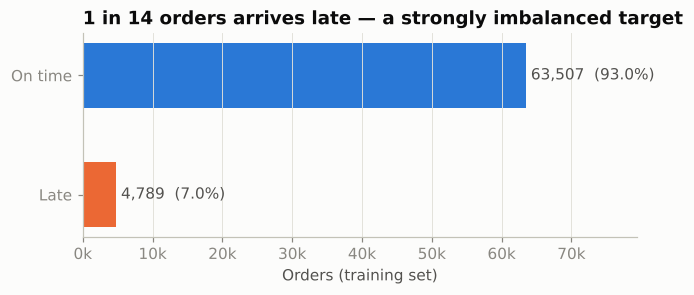

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.barh(["Late", "On time"], [counts[1], counts[0]], color=[LATE, ON_TIME], height=0.55)
for y, v in zip([0, 1], [counts[1], counts[0]]):
    ax.text(v + len(train) * 0.01, y, f"{v:,}  ({v/len(train):.1%})", va="center", color=INK2)
ax.set_xlim(0, counts[0] * 1.25); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.set_xlabel("Orders (training set)")
ax.set_title("1 in 14 orders arrives late — a strongly imbalanced target")
save(fig, "01_target_balance")

**Takeaway — the target.**
* The label is **day-level**: an order is late only if it arrives on a calendar day after the promise. A strict timestamp rule would flip 784 same-day deliveries in train (1.1%) to "late". Day-level is the right business definition (customers are promised a date, not a time), but we should state it as an assumption.
* **Imbalance is ~13:1.** A model that predicts "on time" for everything scores **93% accuracy and catches zero late orders**, so accuracy is meaningless here. For modelling:
  * Primary metrics: **PR-AUC** (average precision) and **ROC-AUC**, plus recall/precision at a chosen threshold.
  * Use **stratified** K-fold CV so every fold keeps ~7% late.
  * Handle imbalance with `class_weight="balanced"` / `scale_pos_weight`, or resampling **inside** the CV folds only.

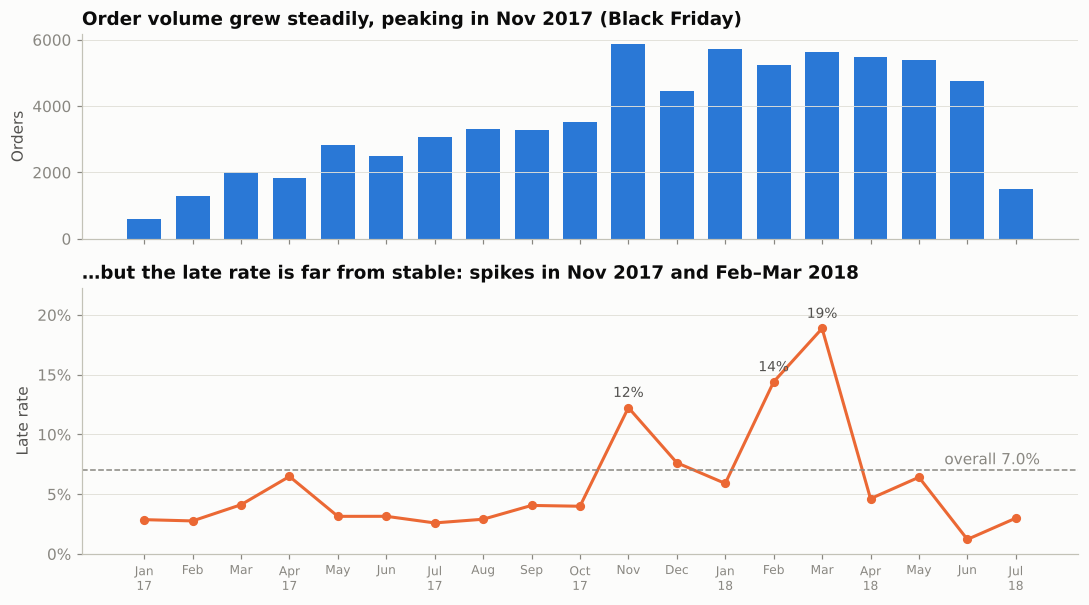

order_purchase_timestamp,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07
orders,592.000000,1302.000000,2015.000000,1819.000000,2828.000000,2507.000000,3080.000000,3303.000000,3275.000000,3531.000000,5879.000000,4454.000000,5711.000000,5242.000000,5628.000000,5468.000000,5405.000000,4755.000000,1502.000000
late_rate,0.029,0.028,0.041,0.065,0.031,0.032,0.026,0.029,0.041,0.040,0.122,0.076,0.059,0.144,0.189,0.046,0.064,0.012,0.030


In [6]:
month = train.order_purchase_timestamp.dt.to_period("M")
monthly = train.groupby(month).agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
labels = [p.strftime("%b\n%y") if p.month in (1, 4, 7, 10) else p.strftime("%b") for p in monthly.index]
x = np.arange(len(monthly))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
a1.bar(x, monthly.orders, color=ON_TIME, width=0.7)
a1.set_ylabel("Orders"); a1.set_title("Order volume grew steadily, peaking in Nov 2017 (Black Friday)")
a1.grid(axis="x", visible=False)
a2.plot(x, monthly.late_rate, color=LATE, lw=2, marker="o", ms=5)
a2.axhline(train.is_late.mean(), color=MUTED, ls="--", lw=1)
a2.text(len(x) - 0.5, train.is_late.mean() + 0.005, f"overall {train.is_late.mean():.1%}", color=MUTED, ha="right")
for i in monthly.late_rate.nlargest(3).index:
    j = list(monthly.index).index(i)
    a2.annotate(f"{monthly.late_rate[i]:.0%}", (j, monthly.late_rate[i]), textcoords="offset points",
                xytext=(0, 7), ha="center", color=INK2, fontsize=9)
a2.set_ylim(0, monthly.late_rate.max() * 1.18); a2.set_yticks(np.arange(0, 0.21, 0.05))
a2.yaxis.set_major_formatter(pct); a2.set_ylabel("Late rate")
a2.set_title("…but the late rate is far from stable: spikes in Nov 2017 and Feb–Mar 2018")
a2.set_xticks(x); a2.set_xticklabels(labels, fontsize=8); a2.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "02_monthly_volume_and_late_rate")
display(monthly.T.style.format("{:.3f}", subset=pd.IndexSlice["late_rate", :]))

**Takeaway — lateness is driven by time-specific shocks.**
* For most of 2017 the late rate sits around **3–4%** (Apr 2017 at 6.5% is the exception). Then three spikes: **Nov 2017 (12.2%)**, **Feb 2018 (14.4%)** and **Mar 2018 (18.9%)**.
* Nov 2017 matches the busiest month (Black Friday: 5,879 training orders, the peak), so **volume overload** is a plausible cause. Feb–Mar 2018 is different: volume was flat, yet lateness tripled. That points to a **system-wide disruption** (carrier, weather, or strike), not anything about the individual orders.
* Implications:
  1. These shocks are the **largest source of error no order-level feature can explain**: a limitation to state in the slides.
  2. `purchase_month` (AUC 0.552) mostly memorises *which* months were bad. It may not generalise ("March is risky" is not a rule). Keep it, but check the model under a **temporal hold-out** (e.g., train on orders before Feb 2018, test after) as a robustness test.
  3. A disruption calendar is the most valuable extra data (§10).

## 3. Leakage audit: what is (and isn't) known at approval time

The RQ restricts us to information available **when the order is approved**. Every column was classified before profiling, so teammates know which ones may enter the model.

In [7]:
roles = {
    "order_id": ("Identifier", "Drop — unique key, no signal"),
    "customer_id": ("Identifier", "Drop — unique per order in Olist (no repeat-customer history)"),
    "order_purchase_timestamp": ("Raw timestamp (known at approval)", "Decompose (done: month/weekday/hour), then drop raw"),
    "order_approved_at": ("Raw timestamp (known at approval)", "Defines prediction time; drop raw after deriving features"),
    "order_estimated_delivery_date": ("Raw timestamp (known at approval)", "Encoded in promised_days_from_approval; drop raw"),
    "order_delivered_customer_date": ("LEAKAGE — known only after delivery", "Must drop: the target is computed from it"),
    "is_late": ("Target", "Label"),
}
leak_tbl = pd.DataFrame([(c, *roles.get(c, ("Feature (known at approval)", "Candidate model input")))
                         for c in df.columns], columns=["column", "role", "action"])
display(leak_tbl.groupby("role").column.apply(lambda s: ", ".join(s)).to_frame("columns"))

,columns
role,
Feature (known at approval),"promised_days_from_approval, approval_lag_hour..."
Identifier,"order_id, customer_id"
LEAKAGE — known only after delivery,order_delivered_customer_date
Raw timestamp (known at approval),"order_purchase_timestamp, order_approved_at, o..."
Target,is_late


**Takeaway.** 22 of the 29 columns are legitimate model inputs. One column, `order_delivered_customer_date`, would leak the answer and must never reach the model. None of the 22 engineered features uses delivery information, so the feature set itself is clean. The one future risk: any feature built from historical delivery times (e.g., a seller's past late rate or a state's typical transit time) must be computed **inside each CV fold / from earlier orders only**.

## 4. Profiling table: every attribute

For each column: type, bounds, % missing, cardinality, summary statistics, skew, share of IQR outliers, noise, distribution shape, and **usefulness**.

*Usefulness* is measured as a **univariate ROC-AUC** against `is_late` (0.50 = no signal; we report max(AUC, 1−AUC) so direction doesn't matter). Categorical columns are scored with a 5-fold **out-of-fold** target-mean encoding so the score isn't inflated by the category simply memorising its own label.

In [8]:
target = "is_late"
features = [c for c in df.columns if leak_tbl.set_index("column").loc[c, "role"].startswith("Feature")]
cat_cols = ["customer_state", "any_seller_state", "primary_product_category", "customer_zip_code_prefix"]
num_cols = [c for c in features if c not in cat_cols]

def auc_numeric(s, y):
    s = s.fillna(s.median())
    a = roc_auc_score(y, s)
    return max(a, 1 - a)

def auc_categorical_oof(s, y, m=20, k=5):
    # out-of-fold smoothed target encoding -> AUC
    s = s.fillna("__missing__").astype(str).reset_index(drop=True)
    y = y.reset_index(drop=True)
    prior, enc = y.mean(), np.zeros(len(s))
    for tr, va in StratifiedKFold(k, shuffle=True, random_state=RANDOM_STATE).split(s, y):
        g = y.iloc[tr].groupby(s.iloc[tr]).agg(["sum", "count"])
        te = (g["sum"] + m * prior) / (g["count"] + m)
        enc[va] = s.iloc[va].map(te).fillna(prior).values
    a = roc_auc_score(y, enc)
    return max(a, 1 - a)

y = train[target]
auc = {c: auc_numeric(train[c], y) for c in num_cols}
auc.update({c: auc_categorical_oof(train[c], y) for c in cat_cols})

In [9]:
# Hand-written notes from inspecting each attribute (plots in §5–§7 back these up)
notes = {
 "order_id": ("str (hash)", "unbounded", "Unique key", "—", "—"),
 "customer_id": ("str (hash)", "unbounded", "Unique per order → carries no customer history", "—", "—"),
 "order_purchase_timestamp": ("datetime", "2017-01 → 2018-07", "None observed", "Uneven over time (growth + Black Friday)", "—"),
 "order_approved_at": ("datetime", "2017-01 → 2018-07", "None observed", "Tracks purchase time", "—"),
 "order_delivered_customer_date": ("datetime", "—", "Post-outcome", "—", "—"),
 "order_estimated_delivery_date": ("date (day precision)", "2017-02 → 2018-08-01", "Rounded to the day → label is day-level", "—", "—"),
 "is_late": ("binary int", "{0,1}", "Day-level comparison (see §2)", "Bernoulli, p ≈ 0.07", "Target"),
 "promised_days_from_approval": ("float, continuous", "> 0, unbounded above", "Long right tail to 154 days (manual/odd promises)", "Bell-shaped core (median ≈ 23 d), right tail", ""),
 "approval_lag_hours": ("float, continuous", "≥ 0, unbounded", "Extreme tail to 741 h (~31 days)", "Bimodal on log scale: instant (<1 h) vs ~1–2 days (likely boleto/bank-slip payments)", ""),
 "purchase_month": ("int, cyclical", "1–12", "Partial-year coverage biases months", "Uneven; Nov–Mar heavy", ""),
 "purchase_weekday": ("int, cyclical", "0–6 (Mon=0)", "None observed", "Near-uniform, slightly lower on weekends", ""),
 "purchase_hour": ("int, cyclical", "0–23", "None observed", "Daytime plateau 10:00–22:00, trough overnight", ""),
 "approval_month": ("int, cyclical", "1–12", "Duplicate of purchase_month for ~98% of orders", "Same as purchase_month", ""),
 "customer_zip_code_prefix": ("int stored, nominal code", "1003–99980", "Numeric value is meaningless (ordering ≠ distance)", "~14k levels, long tail", ""),
 "customer_state": ("categorical (27)", "27 UFs", "None observed", "Dominated by SP (42%), RJ, MG", ""),
 "item_count": ("int, count", "≥ 1", "Few large baskets (max 21)", "Mass at 1 (90%), geometric-like tail", ""),
 "distinct_product_count": ("int, count", "≥ 1", "—", "Mass at 1 (96%)", ""),
 "seller_count": ("int, count", "1–5", "Multi-seller late rate looks implausibly low (check merge)", "Mass at 1 (98.7%)", ""),
 "total_price": ("float, continuous (BRL)", "> 0, unbounded", "Outliers to R$13,440", "Log-normal (right-skewed)", ""),
 "total_freight": ("float, continuous (BRL)", "≥ 0, unbounded", "0.4% free-shipping zeros; outliers to R$1,795", "Log-normal with a spike at 0", ""),
 "mean_product_weight_g": ("float, continuous", "> 0, unbounded", "Seller-entered; round-number heaping (e.g., 100, 200 g)", "Log-normal, heaped", ""),
 "max_product_weight_g": ("float, continuous", "> 0, unbounded", "Same as mean for 1-product orders", "Log-normal, heaped", ""),
 "total_product_volume_cm3": ("float, continuous", "≥ 0, unbounded", "16 zero-volume orders (impossible); outliers to 1.48 M cm³", "Log-normal", ""),
 "mean_distance_km": ("float, continuous", "≥ 0, unbounded", "Zip-centroid straight-line approximation; 20 zeros; a few > 4,500 km (outside Brazil's extent → geo errors)", "Right-skewed, multimodal (SP cluster near 0–400 km)", ""),
 "max_distance_km": ("float, continuous", "≥ 0, unbounded", "Same as mean for 98% of orders", "Same as mean_distance_km", ""),
 "same_state_item_share": ("float, bounded", "0–1", "Effectively binary (0 or 1 for 99% of orders)", "Bimodal at 0 and 1", ""),
 "any_seller_state": ("categorical (22)", "22 UFs", "Single value even for multi-seller orders (ambiguous)", "Dominated by SP (71%)", ""),
 "primary_product_category": ("categorical (71)", "71 levels", "1.5% missing; long tail of rare categories", "Long-tailed", ""),
 "freight_to_price_ratio": ("float, continuous", "≥ 0, unbounded", "Explodes for very cheap items (max 21×)", "Right-skewed", ""),
}

def iqr_outlier_share(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() if iqr > 0 else 0.0

def usefulness(c):
    role = leak_tbl.set_index("column").loc[c, "role"]
    if not role.startswith("Feature"):
        return {"Target": "Target", "Identifier": "Exclude (ID)"}.get(role, "Exclude (leak)" if "LEAK" in role else "Exclude (raw timestamp)")
    a = auc[c]
    return "High" if a >= 0.58 else "Medium" if a >= 0.53 else "Low"

rows = []
for c in df.columns:
    s = train[c]; isnum = pd.api.types.is_numeric_dtype(s) and c not in cat_cols
    dtype, bounds, noise, dist, _ = notes[c]
    rows.append({
        "column": c,
        "role": leak_tbl.set_index("column").loc[c, "role"],
        "type": dtype, "bounds": bounds,
        "pct_missing": s.isna().mean() * 100,
        "n_unique": s.nunique(),
        "min": s.min() if isnum else None, "median": s.median() if isnum else None, "max": s.max() if isnum else None,
        "skew": s.skew() if isnum else None,
        "pct_iqr_outliers": iqr_outlier_share(s) * 100 if isnum and c != target else None,
        "noise / quality notes": noise, "distribution": dist,
        "univariate_auc": auc.get(c),
        "usefulness": usefulness(c),
    })
profile = pd.DataFrame(rows)
profile.to_csv("outputs/profiling_table.csv", index=False)

fmt = {"pct_missing": "{:.2f}%", "n_unique": "{:,}", "min": "{:,.2f}", "median": "{:,.2f}", "max": "{:,.2f}",
       "skew": "{:.1f}", "pct_iqr_outliers": "{:.1f}%", "univariate_auc": "{:.3f}"}
display(profile.style.format(fmt, na_rep="—").hide(axis="index"))

column,role,type,bounds,pct_missing,n_unique,min,median,max,skew,pct_iqr_outliers,noise / quality notes,distribution,univariate_auc,usefulness
order_id,Identifier,str (hash),unbounded,0.00%,"68,296",—,—,—,—,—,Unique key,—,—,Exclude (ID)
customer_id,Identifier,str (hash),unbounded,0.00%,"68,296",—,—,—,—,—,Unique per order → carries no customer history,—,—,Exclude (ID)
order_purchase_timestamp,Raw timestamp (known at approval),datetime,2017-01 → 2018-07,0.00%,"67,994",—,—,—,—,—,None observed,Uneven over time (growth + Black Friday),—,Exclude (raw timestamp)
order_approved_at,Raw timestamp (known at approval),datetime,2017-01 → 2018-07,0.00%,"63,947",—,—,—,—,—,None observed,Tracks purchase time,—,Exclude (raw timestamp)
order_delivered_customer_date,LEAKAGE — known only after delivery,datetime,—,0.00%,"67,786",—,—,—,—,—,Post-outcome,—,—,Exclude (leak)
order_estimated_delivery_date,Raw timestamp (known at approval),date (day precision),2017-02 → 2018-08-01,0.00%,368,—,—,—,—,—,Rounded to the day → label is day-level,—,—,Exclude (raw timestamp)
is_late,Target,binary int,"{0,1}",0.00%,2,0.00,0.00,1.00,3.4,—,Day-level comparison (see §2),"Bernoulli, p ≈ 0.07",—,Target
promised_days_from_approval,Feature (known at approval),"float, continuous","> 0, unbounded above",0.00%,"64,863",0.50,23.26,153.58,1.0,2.3%,Long right tail to 154 days (manual/odd promises),"Bell-shaped core (median ≈ 23 d), right tail",0.522,Low
approval_lag_hours,Feature (known at approval),"float, continuous","≥ 0, unbounded",0.00%,"24,571",0.00,0.35,741.44,4.7,9.6%,Extreme tail to 741 h (~31 days),Bimodal on log scale: instant (<1 h) vs ~1–2 days (likely boleto/bank-slip payments),0.540,Medium
purchase_month,Feature (known at approval),"int, cyclical",1–12,0.00%,12,1.00,5.00,12.00,0.4,0.0%,Partial-year coverage biases months,Uneven; Nov–Mar heavy,0.552,Medium


**Takeaway — profiling summary.**
* **Missingness is tiny**: worst is `primary_product_category` (1.54%), then distance (0.51%). No column needs dropping for missingness.
* **Skew is the main issue.** Price (skew 10.5), freight (14.7), freight-to-price ratio (11.7) and volume (7.8) all have long right tails. 7–14% of values fall outside 1.5×IQR, but these are genuine big orders, not errors. **Log-transform and cap; don't delete.**
* **Three exact duplicates** (Spearman ρ = 1.00, see §8): mean/max distance, mean/max weight, purchase/approval month.
* **Usefulness tiers** (univariate AUC):
  * **High:** `customer_state` 0.647, `mean_distance_km` 0.599, `customer_zip_code_prefix` 0.596, `total_freight` 0.582, `same_state_item_share` 0.582. All geography, directly or indirectly.
  * **Medium:** month (0.552), approval lag (0.540), seller state (0.536), price (0.534), category (0.530).
  * **Low:** promised days *on its own* (0.522; see §6b for why that's misleading), weight, volume, basket counts, hour, weekday, freight ratio.
* `customer_zip_code_prefix` scores high, but it has 13,758 levels and is mostly a finer copy of state and distance. **Prefer state + distance** to avoid overfitting.

In [10]:
# Data-quality issues, quantified on the training set
q = train
issues = pd.DataFrame([
  ("Missing distance (zip prefix not in geolocation table)", "mean/max_distance_km", q.mean_distance_km.isna().sum(), "Impute median + add missing flag (late rate is higher when missing)"),
  ("Missing product category", "primary_product_category", q.primary_product_category.isna().sum(), "Treat as its own level 'unknown'"),
  ("Missing product weight", "mean/max_product_weight_g", q.mean_product_weight_g.isna().sum(), "Impute median"),
  ("Zero distance (same zip prefix as seller)", "mean_distance_km", (q.mean_distance_km == 0).sum(), "Plausible; keep"),
  ("Distance > 4,500 km (exceeds Brazil's extent → geocoding error)", "max_distance_km", (q.max_distance_km > 4500).sum(), "Set to NaN and impute"),
  ("Zero product volume (impossible)", "total_product_volume_cm3", (q.total_product_volume_cm3 == 0).sum(), "Set to NaN and impute"),
  ("Zero freight (free shipping)", "total_freight", (q.total_freight == 0).sum(), "Plausible; keep (log1p handles 0)"),
  ("Approval lag > 7 days", "approval_lag_hours", (q.approval_lag_hours > 168).sum(), "Cap at 99th percentile"),
  ("Promised window > 60 days", "promised_days_from_approval", (q.promised_days_from_approval > 60).sum(), "Cap at 99th percentile"),
  ("purchase_month ≠ approval_month", "approval_month", (q.purchase_month != q.approval_month).sum(), "Redundant; drop approval_month"),
  ("Multi-seller orders (late rate anomalously low)", "seller_count", (q.seller_count > 1).sum(), "Keep as binary flag; confirm merge logic"),
], columns=["issue", "column", "orders_in_train", "recommended handling"])
issues["pct_of_train"] = issues.orders_in_train / len(q) * 100
issues.to_csv("outputs/data_quality_issues.csv", index=False)
display(issues.style.format({"orders_in_train": "{:,}", "pct_of_train": "{:.2f}%"}).hide(axis="index"))
print(f"Late rate when distance missing: {q[q.mean_distance_km.isna()].is_late.mean():.1%}  vs  overall {q.is_late.mean():.1%}")

issue,column,orders_in_train,recommended handling,pct_of_train
Missing distance (zip prefix not in geolocation table),mean/max_distance_km,349,Impute median + add missing flag (late rate is higher when missing),0.51%
Missing product category,primary_product_category,"1,051",Treat as its own level 'unknown',1.54%
Missing product weight,mean/max_product_weight_g,12,Impute median,0.02%
Zero distance (same zip prefix as seller),mean_distance_km,15,Plausible; keep,0.02%
"Distance > 4,500 km (exceeds Brazil's extent → geocoding error)",max_distance_km,3,Set to NaN and impute,0.00%
Zero product volume (impossible),total_product_volume_cm3,12,Set to NaN and impute,0.02%
Zero freight (free shipping),total_freight,266,Plausible; keep (log1p handles 0),0.39%
Approval lag > 7 days,approval_lag_hours,48,Cap at 99th percentile,0.07%
Promised window > 60 days,promised_days_from_approval,122,Cap at 99th percentile,0.18%
purchase_month ≠ approval_month,approval_month,"1,200",Redundant; drop approval_month,1.76%


Late rate when distance missing: 8.3%  vs  overall 7.0%


**Takeaway — data quality.** Every issue touches **under 2% of orders**, so cleaning is about robustness, not rescue.
* Orders with **missing distance are late more often (8.3% vs 7.0%)**. Missingness carries a little signal, so impute *and* keep a flag.
* **Impossible values** (12 zero-volume orders, 3 distances beyond Brazil's ~4,400 km extent) should become NaN and be imputed.
* **Open question for whoever built the merge:** multi-seller orders show a 1.5% late rate vs 7.1% for single-seller orders. That gap is too large to be plausible on its own. Worth checking how the delivery date was aggregated when an order ships from several sellers.

## 5. Distributions of the numeric attributes, split by outcome

Each panel overlays the distribution for on-time (blue) and late (orange) orders, normalised so the two shapes are comparable despite the 13:1 imbalance. Skewed money/size/distance features are drawn on a **log axis** (the transformation we recommend in §9).

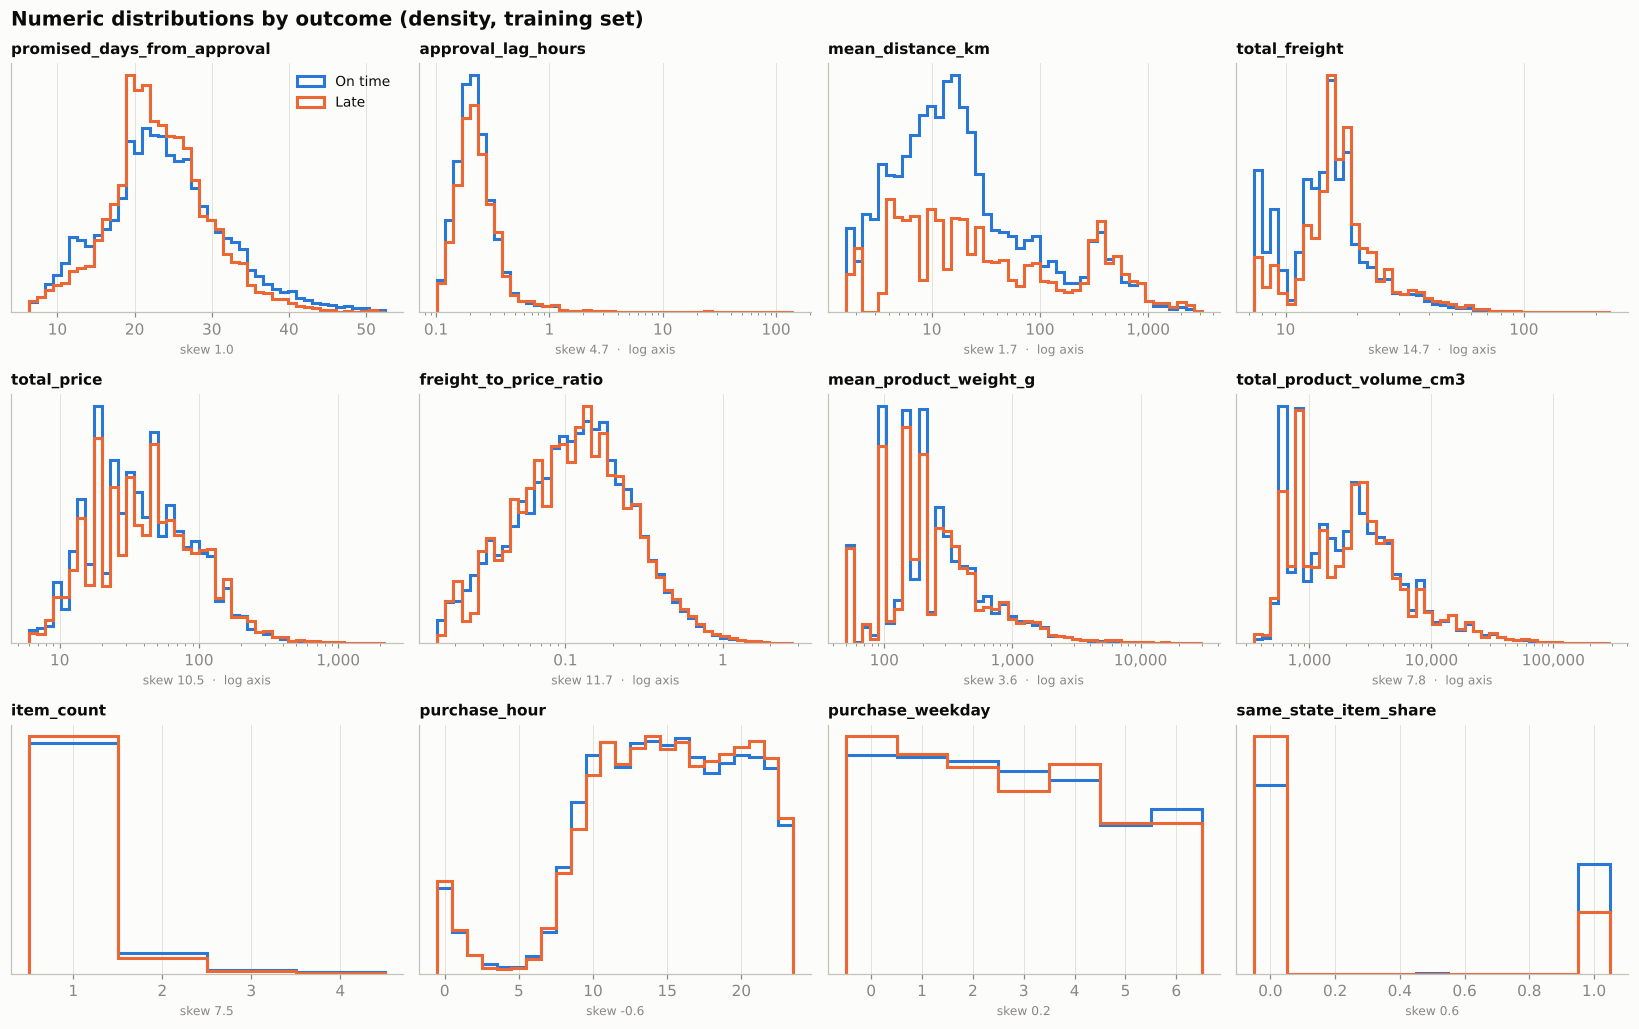

In [11]:
plot_num = ["promised_days_from_approval", "approval_lag_hours", "mean_distance_km", "total_freight",
            "total_price", "freight_to_price_ratio", "mean_product_weight_g", "total_product_volume_cm3",
            "item_count", "purchase_hour", "purchase_weekday", "same_state_item_share"]
log_x = {"approval_lag_hours", "mean_distance_km", "total_freight", "total_price",
         "freight_to_price_ratio", "mean_product_weight_g", "total_product_volume_cm3"}
discrete = {"item_count", "purchase_hour", "purchase_weekday", "same_state_item_share"}

fig, axes = plt.subplots(3, 4, figsize=(15, 9.5))
for ax, c in zip(axes.flat, plot_num):
    s = train[c].dropna()
    if c in discrete:
        lo, hi = s.quantile(0), min(s.quantile(0.995), s.max())
        bins = np.arange(lo - 0.5, hi + 1.5, 1) if c != "same_state_item_share" else np.linspace(-0.05, 1.05, 12)
    elif c in log_x:
        pos = s[s > 0]
        bins = np.logspace(np.log10(pos.quantile(0.001)), np.log10(pos.quantile(0.999)), 45)
    else:
        bins = np.linspace(s.quantile(0.001), s.quantile(0.995), 45)
    for lbl, col in [(0, ON_TIME), (1, LATE)]:
        v = train.loc[train.is_late == lbl, c].dropna()
        ax.hist(v, bins=bins, density=True, histtype="step", lw=2, color=col,
                label="On time" if lbl == 0 else "Late")
    if c in log_x: ax.set_xscale("log"); tidy_log_axis(ax)
    ax.set_title(c, fontsize=10); ax.set_yticks([]); ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"skew {train[c].skew():.1f}" + ("  ·  log axis" if c in log_x else ""), fontsize=8, color=MUTED)
axes.flat[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Numeric distributions by outcome (density, training set)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "03_numeric_distributions_by_outcome")

**Takeaway — distributions.**
* **Distance separates the classes most visibly.** On-time orders pile up at very short distances (the same-city São Paulo cluster); late orders are spread toward hundreds and thousands of km. `same_state_item_share` tells the same story: late orders are far more often **cross-state**.
* `total_freight` mirrors distance, because Olist prices shipping by distance (ρ = 0.58).
* `promised_days_from_approval`: late orders concentrate at **18–28-day promises** and are rare at very long promises.
* Price, weight, volume, freight ratio, approval lag, hour and weekday: the two curves **almost overlap**, so these are weak on their own.
* On the log axis, the skewed money/size features become roughly bell-shaped, which supports a **`log1p` transform**. Weight shows **round-number heaping** (spikes at round values such as 100 and 200 g): sellers type estimates, so treat weight as noisy.

## 6. Risk curves: how the late rate changes across each numeric feature

Distributions show *shape*; risk curves show *signal*. Each feature is cut into deciles (equal-count bins) and we plot the late rate in each bin. A flat line at the dashed overall rate means no signal.

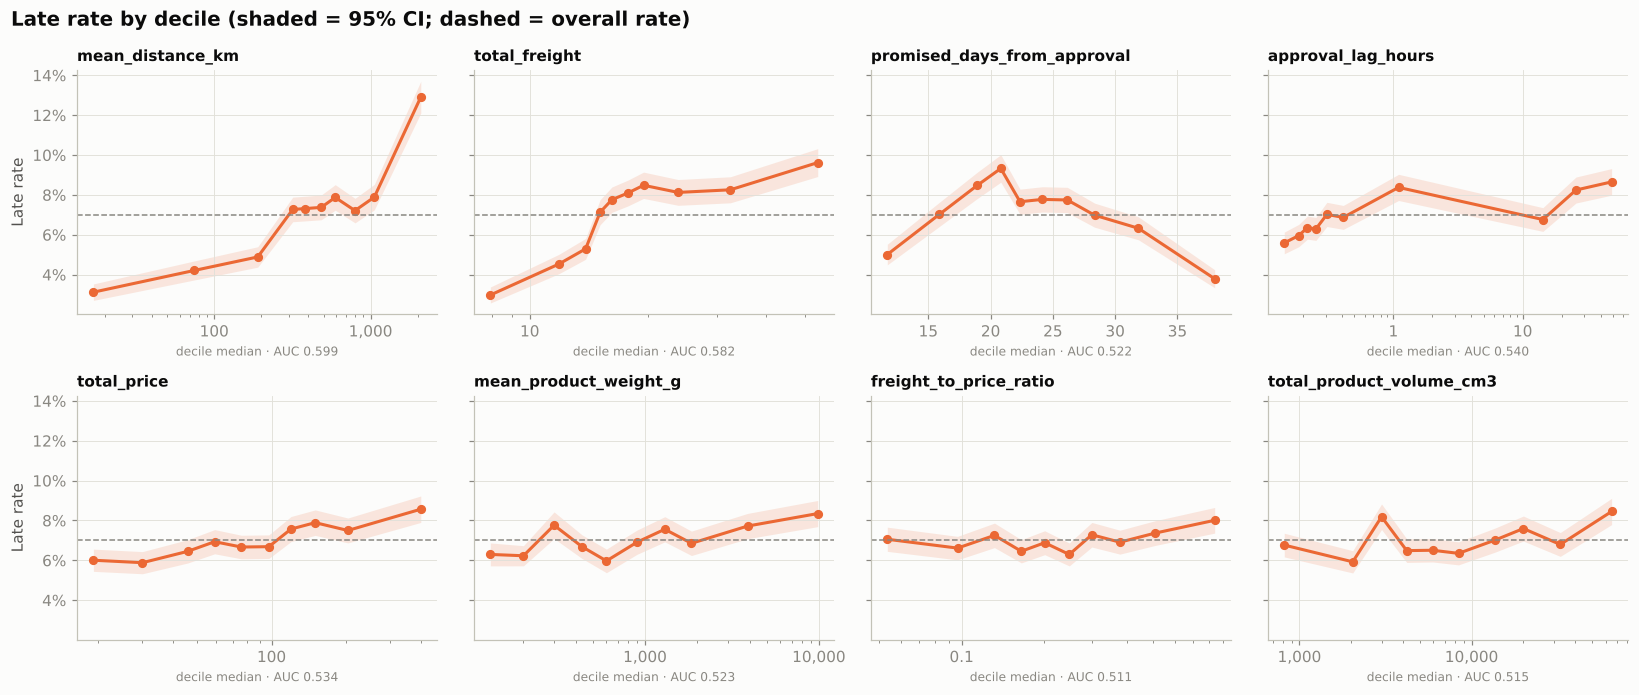

In [12]:
risk_feats = ["mean_distance_km", "total_freight", "promised_days_from_approval", "approval_lag_hours",
              "total_price", "mean_product_weight_g", "freight_to_price_ratio", "total_product_volume_cm3"]
base = train.is_late.mean()
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharey=True)
risk_tables = {}
for ax, c in zip(axes.flat, risk_feats):
    b = pd.qcut(train[c], 10, duplicates="drop")
    g = train.groupby(b, observed=True).agg(x=(c, "median"), rate=("is_late", "mean"), n=("is_late", "size"))
    se = np.sqrt(g.rate * (1 - g.rate) / g.n)
    risk_tables[c] = g
    ax.fill_between(g.x, g.rate - 1.96 * se, g.rate + 1.96 * se, color=LATE, alpha=0.15, lw=0)
    ax.plot(g.x, g.rate, color=LATE, lw=2, marker="o", ms=5)
    ax.axhline(base, color=MUTED, ls="--", lw=1)
    if c in log_x: ax.set_xscale("log"); tidy_log_axis(ax)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel(f"decile median · AUC {auc[c]:.3f}", fontsize=8, color=MUTED)
    ax.yaxis.set_major_formatter(pct)
for ax in axes[:, 0]: ax.set_ylabel("Late rate")
fig.suptitle("Late rate by decile (shaded = 95% CI; dashed = overall rate)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "04_risk_curves_numeric")

**Takeaway — risk curves.**
* **Distance is the clearest driver:** late rate climbs from **3.1%** in the nearest decile (< 36 km) to **12.9%** in the farthest (> 1,455 km), a **4× increase**. The jump near 300 km roughly marks leaving São Paulo state.
* **Freight** rises from **3.0% to 9.6%**, mostly flattening above ~R$16. It's largely a distance proxy.
* **Promised days is non-monotonic**: risk rises to **9.3%** around 21 days, then falls to **3.8%** for the longest promises. A linear model will miss this inverted-U; trees catch it automatically. For logistic regression, bin it or use splines.
* **Approval lag** has a mild positive trend (5.6% → 8.7%). Orders that sit unapproved for ~1–2 days (likely bank-slip payments) carry a bit more risk.
* **Price, weight, volume, freight ratio** stay within ~±1.5 points of the 7% baseline. Weak signal.

### 6b. The key interaction: distance vs. the promised window

`promised_days_from_approval` is nearly useless on its own (AUC ≈ 0.52) because Olist already pads promises for far-away customers. The question that matters is whether the promise is long enough **for that distance**.

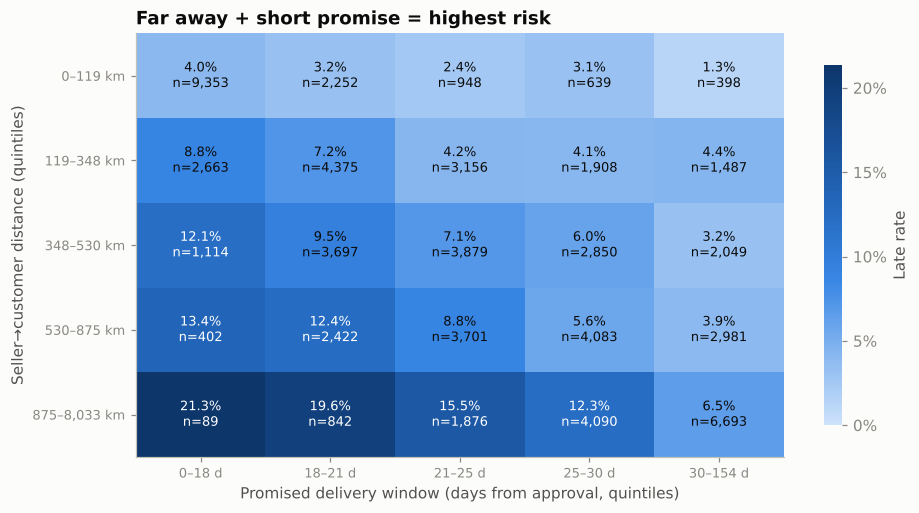

In [13]:
d_bin = pd.qcut(train.mean_distance_km, 5)
p_bin = pd.qcut(train.promised_days_from_approval, 5)
heat = train.pivot_table(index=d_bin, columns=p_bin, values="is_late", aggfunc="mean", observed=True)
n = train.pivot_table(index=d_bin, columns=p_bin, values="is_late", aggfunc="size", observed=True)

def lab(iv, unit):
    return f"{max(iv.left, 0):,.0f}–{iv.right:,.0f} {unit}"

fig, ax = plt.subplots(figsize=(9.5, 5))
im = ax.imshow(heat.values, cmap=SEQ, aspect="auto", vmin=0, vmax=heat.values.max())
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.1%}\nn={n.values[i, j]:,}", ha="center", va="center", fontsize=8.5,
                color="white" if v > heat.values.max() * 0.55 else INK)
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels([lab(c, "d") for c in heat.columns], fontsize=8.5)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels([lab(r, "km") for r in heat.index], fontsize=8.5)
ax.set_xlabel("Promised delivery window (days from approval, quintiles)")
ax.set_ylabel("Seller→customer distance (quintiles)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, format=pct, shrink=0.85, ticks=np.arange(0, 0.25, 0.05)); cb.set_label("Late rate"); cb.outline.set_visible(False)
ax.set_title("Far away + short promise = highest risk")
save(fig, "05_distance_x_promise_heatmap")

**Takeaway — this is the headline insight.** Across each row, risk **generally falls as the promise lengthens**; down each column, it **rises with distance**.
* Far (> 875 km) with an 18–21-day promise: **19.6% late** (n = 842). The 0–18-day cell is even higher (21.3%) but has only 89 orders.
* Near (< 119 km) with a 30+ day promise: **1.3% late**, a **~15× spread**.
* Neither variable captures this alone. Olist already pads promises for distant customers (ρ = 0.64 between distance and promised days), but **not enough** for the longest routes.
* **Action:** engineer a *promise-relative-to-distance* feature. In §9, `promise_days_per_100km` reaches **AUC 0.634**, up from 0.522 for the raw promise — the strongest numeric feature we have.
* **One-liner for the slides:** *"Late deliveries happen when the promise is too short for the distance."*

## 7. Categorical attributes

Late rate by group, with order counts so small groups aren't over-read. Bars are sorted by late rate; the dashed line is the overall rate.

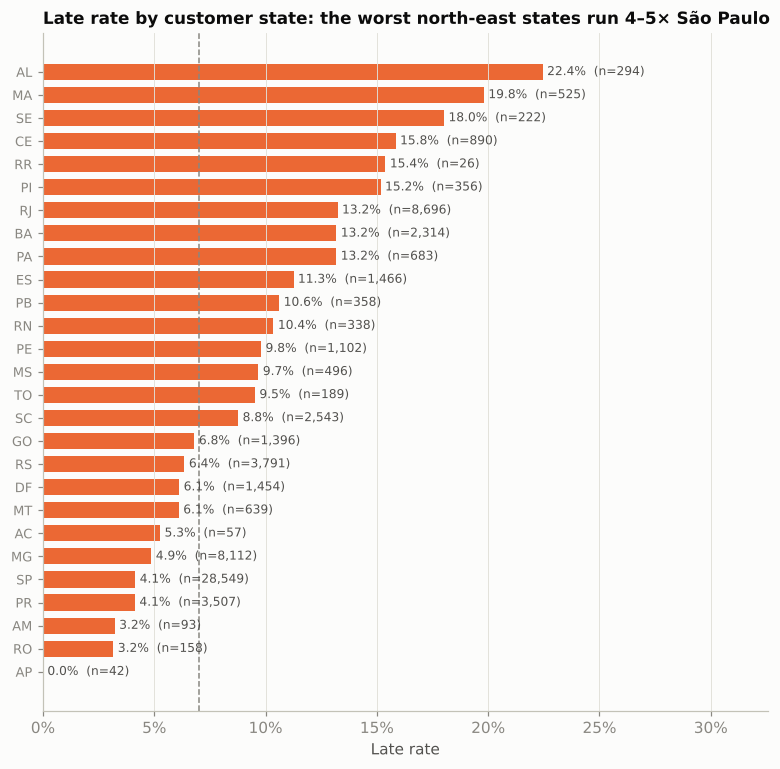

In [14]:
def rate_bars(ax, col, data, top=None, min_n=0, title=None):
    g = data.groupby(col).is_late.agg(rate="mean", n="size")
    g = g[g.n >= min_n]
    if top: g = g.sort_values("n", ascending=False).head(top)
    g = g.sort_values("rate")
    ax.barh(g.index.astype(str), g.rate, color=LATE, height=0.7)
    ax.axvline(base, color=MUTED, ls="--", lw=1)
    for i, (r, k) in enumerate(zip(g.rate, g.n)):
        ax.text(r + 0.002, i, f"{r:.1%}  (n={k:,})", va="center", fontsize=8, color=INK2)
    ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, g.rate.max() * 1.45)
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(title or col, fontsize=11)
    return g

fig, ax = plt.subplots(figsize=(8.5, 8))
state_tbl = rate_bars(ax, "customer_state", train, title="Late rate by customer state: the worst north-east states run 4–5× São Paulo")
ax.set_xlabel("Late rate")
save(fig, "06_late_rate_by_customer_state")

**Takeaway — customer state is the single strongest feature (AUC 0.647).**
* North-east states are worst: **Alagoas 22.4%, Maranhão 19.8%, Sergipe 18.0%, Ceará 15.8%**, vs **São Paulo 4.1%**, which is 42% of orders.
* **Rio de Janeiro is the surprise:** 13.2% late on 8,696 orders, **2.7× Minas Gerais (4.9%)**. Yet both have similar median distances (~395 vs ~491 km) and similar promises (~24 days). So geography matters **beyond distance**: regional carrier performance and last-mile conditions. This is why state adds signal on top of km.
* Small states are unreliable (Roraima n = 26; Amapá n = 42 with 0% late). Use **smoothed target encoding** (fit within CV folds) or one-hot with rare states grouped.

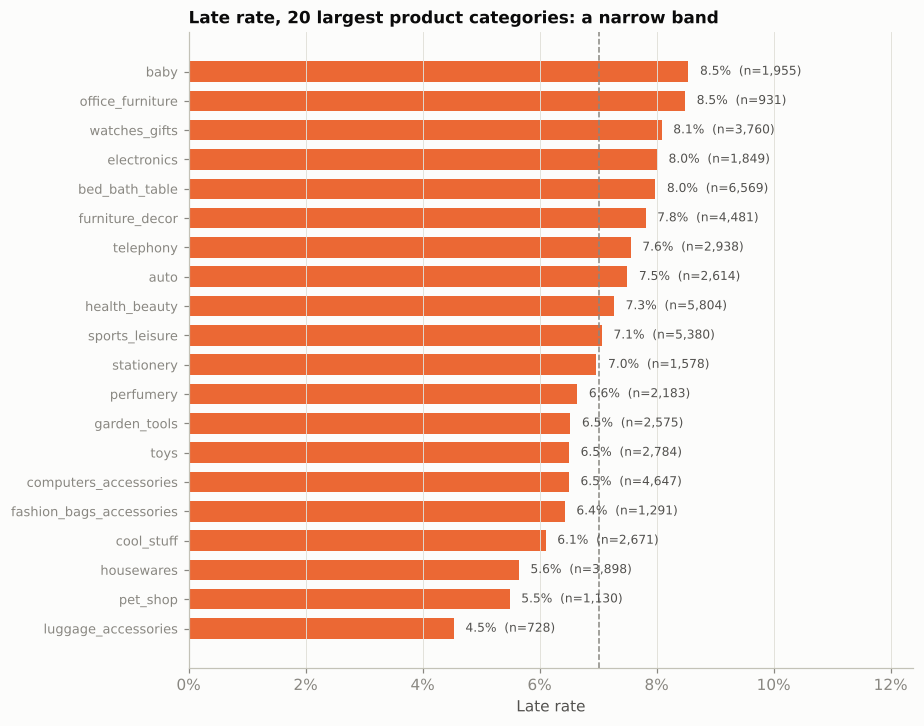

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 7.5))
cat_tbl = rate_bars(ax, "primary_product_category", train, top=20,
                    title="Late rate, 20 largest product categories: a narrow band")
ax.set_xlabel("Late rate")
save(fig, "07_late_rate_by_category")

**Takeaway — product category barely matters.** The 20 largest categories all fall between **4.5% (luggage) and 8.5% (baby, office furniture)**, and overall category AUC is just 0.530. What is being shipped matters far less than *where it's going*. Group categories with fewer than ~200 orders into "other", keep missing as "unknown", and expect a low importance ranking.

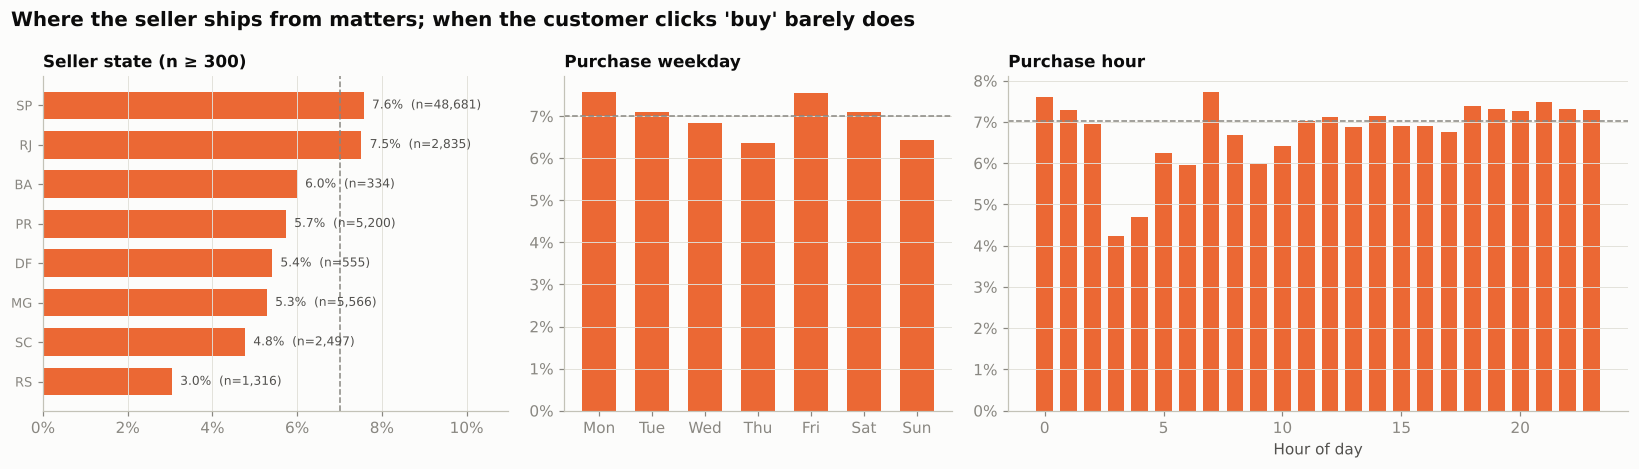

,late rate,orders
1 seller,7.1%,"67,416"
2+ sellers,1.5%,880
1 item,7.2%,"61,370"
2+ items,5.5%,"6,926"


In [16]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.2, 1, 1.6]})
seller_tbl = rate_bars(axes[0], "any_seller_state", train, min_n=300, title="Seller state (n ≥ 300)")
wd = train.groupby("purchase_weekday").is_late.agg(rate="mean", n="size")
axes[1].bar(days, wd.rate, color=LATE, width=0.65); axes[1].axhline(base, color=MUTED, ls="--", lw=1)
axes[1].yaxis.set_major_formatter(pct); axes[1].set_title("Purchase weekday", fontsize=11); axes[1].grid(axis="x", visible=False)
hr = train.groupby("purchase_hour").is_late.agg(rate="mean", n="size")
axes[2].bar(hr.index, hr.rate, color=LATE, width=0.7); axes[2].axhline(base, color=MUTED, ls="--", lw=1)
axes[2].yaxis.set_major_formatter(pct); axes[2].set_title("Purchase hour", fontsize=11); axes[2].grid(axis="x", visible=False)
axes[2].set_xlabel("Hour of day")
fig.suptitle("Where the seller ships from matters; when the customer clicks 'buy' barely does",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "08_seller_state_weekday_hour")

basket = train.assign(multi_seller=np.where(train.seller_count > 1, "2+ sellers", "1 seller"),
                      basket=np.where(train.item_count > 1, "2+ items", "1 item"))
display(pd.concat([basket.groupby("multi_seller").is_late.agg(["mean", "size"]),
                   basket.groupby("basket").is_late.agg(["mean", "size"])])
        .rename(columns={"mean": "late rate", "size": "orders"}).style.format({"late rate": "{:.1%}", "orders": "{:,}"}))

**Takeaway — seller location, timing and basket.**
* **Seller state** ranges from **3.0% (RS) to 7.6% (SP)**. São Paulo sellers ship 71% of orders and are slightly *above* average, likely because they ship to every corner of the country. Moderate signal (AUC 0.536).
* **Weekday (6.4–7.6%) and hour** are essentially flat. The dip at 3–4 a.m. rests on very few orders. Low value; keep only as cheap cyclical features.
* **Baskets:** multi-item orders are slightly *less* often late (5.5% vs 7.2%). Multi-seller orders show 1.5% vs 7.1%, which is flagged in §4 for a merge check.

## 8. Correlations

**8a.** Spearman rank correlation between numeric attributes (rank-based, so robust to the heavy skew seen in §5). Used here to find **redundant** features.
**8b.** Every feature's univariate AUC, numeric and categorical together, ranked: the usefulness column of the profiling table, visualised.

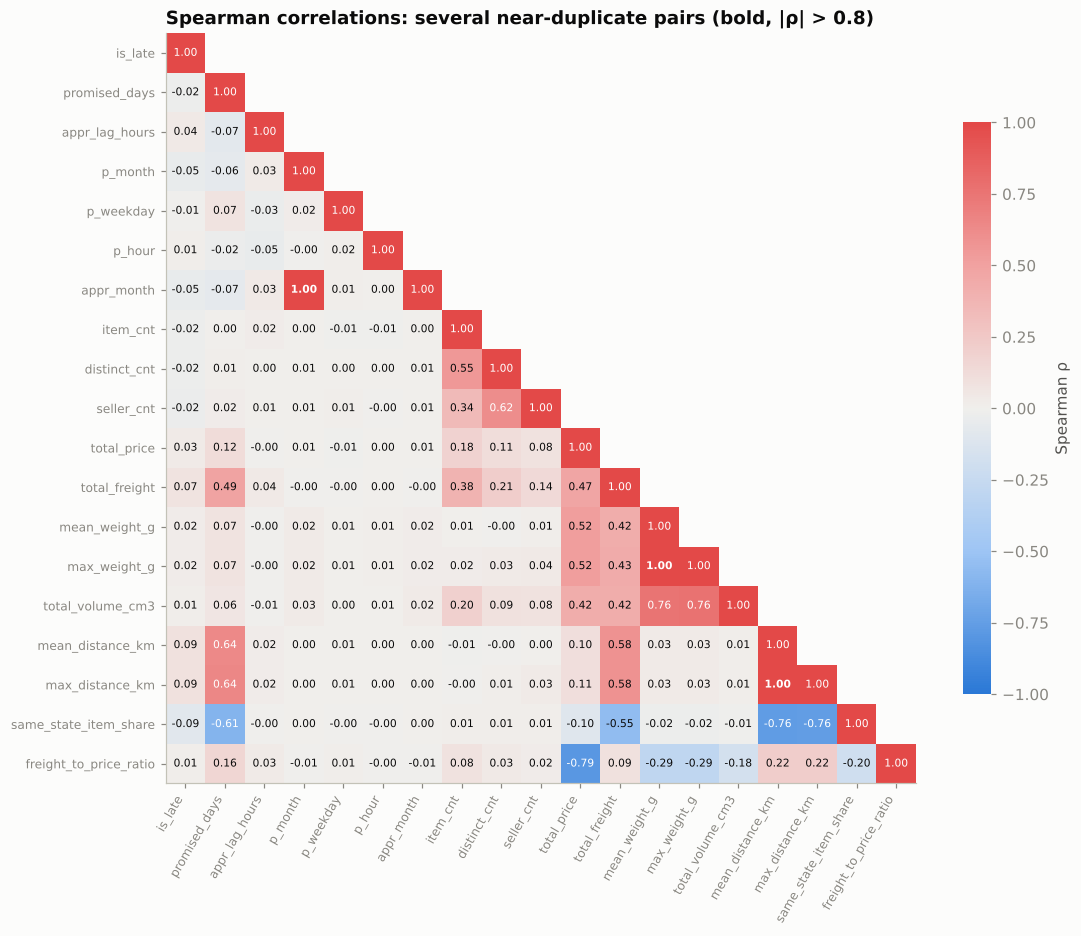

level_0,level_1,rho
max_product_weight_g,mean_product_weight_g,1.00
max_distance_km,mean_distance_km,1.00
approval_month,purchase_month,1.00


Spearman ρ with is_late (top 6 by magnitude):
mean_distance_km         0.088
max_distance_km          0.087
same_state_item_share   -0.087
total_freight            0.073
purchase_month          -0.046
approval_month          -0.045


In [17]:
corr_cols = ["is_late"] + [c for c in num_cols if c != "customer_zip_code_prefix"]
corr = train[corr_cols].corr(method="spearman")
short = {c: c.replace("_from_approval", "").replace("_product", "").replace("_count", "_cnt")
              .replace("purchase_", "p_").replace("approval_", "appr_") for c in corr.columns}
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
im = ax.imshow(np.ma.masked_array(corr.values, mask), cmap=DIV, vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else INK, fontweight="bold" if abs(v) > 0.8 and i != j else "normal")
ax.set_xticks(range(len(corr))); ax.set_xticklabels([short[c] for c in corr.columns], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels([short[c] for c in corr.columns], fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75); cb.set_label("Spearman ρ"); cb.outline.set_visible(False)
ax.set_title("Spearman correlations: several near-duplicate pairs (bold, |ρ| > 0.8)")
save(fig, "09_spearman_correlation_matrix")

pairs = (corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack()
         .rename("rho").reset_index().query("abs(rho) > 0.8").sort_values("rho", ascending=False))
display(pairs.style.format({"rho": "{:.2f}"}).hide(axis="index"))
print("Spearman ρ with is_late (top 6 by magnitude):")
print(corr["is_late"].drop("is_late").sort_values(key=abs, ascending=False).head(6).round(3).to_string())

**Takeaway — correlations.**
* **Drop one of each exact-duplicate pair** (ρ = 1.00): keep `mean_distance_km`, `mean_product_weight_g`, `purchase_month`; drop the `max_*` versions and `approval_month`.
* **A geography cluster:** distance correlates with promised days (0.64), freight (0.58), and same-state share (−0.76). Olist sets both freight and the promise from distance. Multicollinearity matters for logistic regression (regularise, or rely on the engineered ratio); trees are unaffected.
* `total_price` vs `freight_to_price_ratio` (−0.79) is correlated by construction.
* **The strongest correlation with `is_late` is only 0.09** (distance). There is no simple linear relationship: the signal lives in **non-linearities and interactions** (§6, §6b). Expect tree ensembles (Random Forest, gradient boosting) to beat a plain logistic regression unless it gets engineered features.

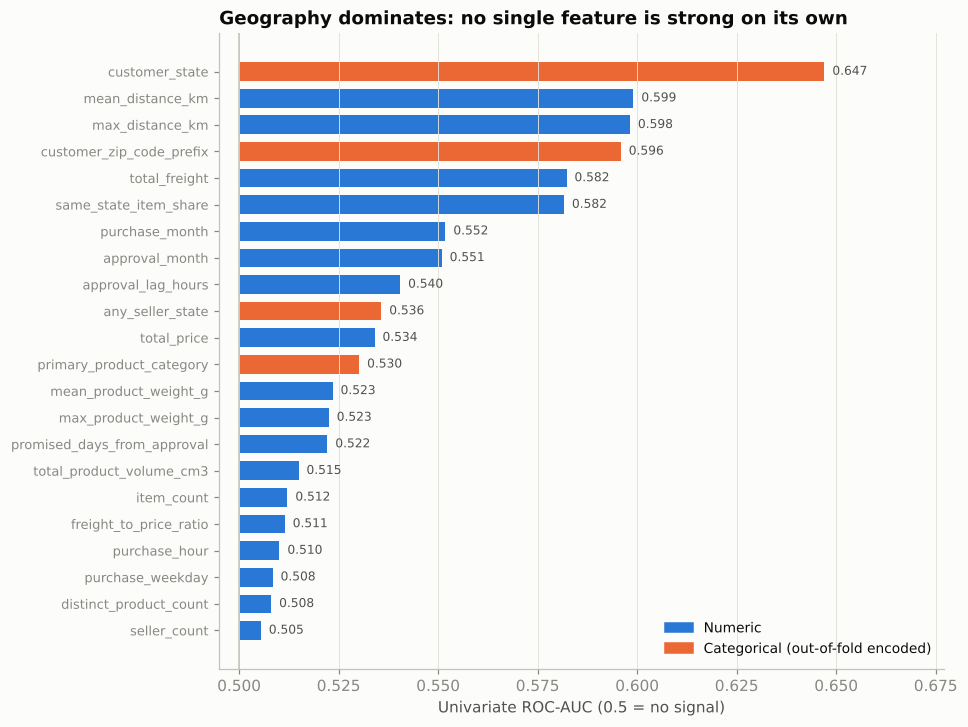

In [18]:
auc_s = pd.Series(auc).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 7.5))
cols = [LATE if c in cat_cols else ON_TIME for c in auc_s.index]
ax.barh(auc_s.index, auc_s.values - 0.5, left=0.5, color=cols, height=0.7)
for i, v in enumerate(auc_s.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=INK2)
ax.axvline(0.5, color=AXIS, lw=1)
ax.set_xlim(0.495, auc_s.max() + 0.03); ax.set_xlabel("Univariate ROC-AUC (0.5 = no signal)")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ON_TIME, label="Numeric"), Patch(color=LATE, label="Categorical (out-of-fold encoded)")],
          loc="lower right", fontsize=9)
ax.set_title("Geography dominates: no single feature is strong on its own")
save(fig, "10_univariate_auc_ranking")

**Takeaway — usefulness ranking.** **Geography holds the top six spots** (state, distance ×2, zip, freight, same-state share). Time comes next (month, approval lag). Product attributes and purchase timing are at the bottom. No feature passes 0.65 on its own, so predictive power will come from **combining** features, especially distance × promise.

## 9. Promising transformations (hand-off to *Prepare the Data*)

Each one is tested quickly below with the same univariate AUC, so the team can see which are worth building into the pipeline. Anything that uses the target (encodings, typical transit times) is fit on **training folds only**.

In [19]:
cand = train.copy()
# 1) Promise relative to distance: days of promise per 100 km
cand["promise_days_per_100km"] = cand.promised_days_from_approval / (cand.mean_distance_km.fillna(cand.mean_distance_km.median()) / 100 + 1)
# 2) Promise slack vs. typical transit time for the customer's state (fit out-of-fold: uses delivery times)
cand["actual_days"] = (cand.order_delivered_customer_date - cand.order_approved_at).dt.total_seconds() / 86400
slack = np.zeros(len(cand)); cand = cand.reset_index(drop=True)
for tr, va in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(cand, cand.is_late):
    med = cand.iloc[tr].groupby("customer_state").actual_days.median()
    slack[va] = cand.promised_days_from_approval.iloc[va] - cand.customer_state.iloc[va].map(med).fillna(med.median()).values
cand["promise_slack_vs_state_typical"] = slack
# 3) Log transforms of skewed features (monotone, so AUC unchanged — the benefit is for linear/distance-based models)
# 4) Cyclical encodings of hour (helps linear models; trees don't need it)
cand["hour_sin"] = np.sin(2 * np.pi * cand.purchase_hour / 24)
# 5) Simple flags
cand["multi_seller"] = (cand.seller_count > 1).astype(int)
cand["is_weekend_purchase"] = (cand.purchase_weekday >= 5).astype(int)
cand["distance_missing"] = cand.mean_distance_km.isna().astype(int)
cand["cross_state"] = (cand.same_state_item_share < 1).astype(int)
# 6) Customer region (5 macro-regions) — lower-cardinality version of state
region = {**dict.fromkeys(["SP", "RJ", "MG", "ES"], "Southeast"), **dict.fromkeys(["PR", "SC", "RS"], "South"),
          **dict.fromkeys(["DF", "GO", "MT", "MS"], "Center-West"),
          **dict.fromkeys(["BA", "SE", "AL", "PE", "PB", "RN", "CE", "PI", "MA"], "Northeast"),
          **dict.fromkeys(["PA", "AM", "AP", "RR", "AC", "RO", "TO"], "North")}
cand["customer_region"] = cand.customer_state.map(region)
cand["route_region"] = cand.any_seller_state.map(region).fillna("?") + "→" + cand.customer_region

new = {"promise_days_per_100km": "numeric", "promise_slack_vs_state_typical": "numeric",
       "hour_sin": "numeric", "multi_seller": "numeric", "is_weekend_purchase": "numeric",
       "distance_missing": "numeric", "cross_state": "numeric",
       "customer_region": "cat", "route_region": "cat"}
trans_auc = {c: (auc_numeric(cand[c], cand.is_late) if k == "numeric" else auc_categorical_oof(cand[c], cand.is_late))
             for c, k in new.items()}
ref = {"promised_days_from_approval (raw)": auc["promised_days_from_approval"],
       "mean_distance_km (raw)": auc["mean_distance_km"], "customer_state (raw)": auc["customer_state"]}
display(pd.Series({**trans_auc, **ref}, name="univariate AUC").sort_values(ascending=False).to_frame()
        .style.format("{:.3f}").bar(color="#f5c6b1", vmin=0.5))

,univariate AUC
customer_state (raw),0.647
promise_days_per_100km,0.634
promise_slack_vs_state_typical,0.615
mean_distance_km (raw),0.599
cross_state,0.581
route_region,0.575
customer_region,0.552
promised_days_from_approval (raw),0.522
hour_sin,0.509
multi_seller,0.505


**Takeaway — transformations, ranked for the *Prepare the Data* stage.**

| Transformation | Univariate AUC | Recommendation |
|---|---|---|
| `promise_days_per_100km` (promise ÷ distance) | **0.634** (vs 0.522 raw) | **Build it.** Best numeric feature |
| `promise_slack_vs_state_typical` (promise − typical transit to that state) | 0.615 | Build it, but **fit the typical-transit table inside each CV fold** (it uses delivery times) |
| `cross_state` flag | 0.581 | Simple, interpretable; same info as `same_state_item_share` |
| `route_region` (seller → customer region) | 0.575 | Weaker than state alone; optional |
| `customer_region` (5 regions) | 0.552 | Loses information vs state; use only to smooth rare states |
| hour sin/cos, weekend, multi-seller, distance-missing flags | ~0.50–0.51 | Low priority; cheap to include |

**Also apply in the pipeline (all fitted on training folds only):**
* `log1p` on price, freight, weight, volume, distance, approval lag and freight ratio; cap at the 99th percentile.
* Drop `max_distance_km`, `max_product_weight_g`, `approval_month`, the IDs, raw timestamps, and `order_delivered_customer_date`.
* Impute: median for numerics (+ missing-distance flag); `"unknown"` for category.
* Encode: smoothed target encoding (or one-hot) for `customer_state`, `any_seller_state`, `primary_product_category`. Drop `customer_zip_code_prefix`.
* Scale: `StandardScaler` after logs for logistic regression / SVM / kNN; not needed for trees.

## 10. Extra data that would help

| Extra data | Why it should help | Available at approval? | Source |
|---|---|---|---|
| **Seller's historical late rate & handling time** | Seller reliability is a likely driver we can't see in a single order | Yes, if computed from *earlier* orders only | Olist `order_items` + `orders` (raw tables) |
| **`shipping_limit_date`** (seller's deadline to hand over to the carrier) | Tight dispatch deadlines vs. promise window | Yes | Olist `order_items` (raw) |
| **Payment type** (credit card vs. boleto) | Explains the bimodal approval lag | Yes | Olist `order_payments` (raw) |
| **Repeat-customer flag** (`customer_unique_id`) | Our `customer_id` is unique per order, so history is lost | Yes | Olist `customers` (raw) |
| **Calendar of disruptions** (Black Friday, Carnival, the May 2018 truckers' strike, postal strikes) | The Nov 2017 and Feb–Mar 2018 spikes look like system-wide shocks, not order traits | Partly (known events) | Public news / holiday calendars |
| **Road distance / carrier route**, not straight-line distance | Straight-line km understates remote north/north-east routes | Yes | Routing API; Correios zone tables |
| **Carrier identity / service level** | Different carriers, different reliability | Yes, in principle | Not in the public dataset |

## 11. Summary of what we learned

**Key findings**
1. **1 in 14 orders arrives late (7.0%, ~13:1 imbalance).** Accuracy is useless here (93% by predicting "never late"); evaluate with PR-AUC, ROC-AUC and recall.
2. **"Late deliveries happen when the promise is too short for the distance."** Far + short-promise orders run ~20% late; near + long-promise orders ~1%.
3. **Where the order goes matters most.** Customer state is the strongest single predictor (AUC 0.647). North-east states run 4–5× São Paulo's late rate.
4. **Rio de Janeiro is late 2.7× as often as Minas Gerais** despite similar distance and promise, so regional logistics matter beyond kilometres.
5. **What is ordered barely matters.** Category, weight, volume and price all sit near the baseline.
6. **Lateness comes in system-wide waves** (Nov 2017: 12%; Feb–Mar 2018: 14–19%) that no order-level feature can explain.
7. **No single feature is strong on its own** (max univariate AUC 0.65; max |ρ| with the target 0.09). The signal is non-linear and interactive, which favours tree ensembles.

**Assumptions** 
* "Late" is judged by calendar day, against the promise shown at checkout.
* Straight-line seller→customer distance from zip-code centroids is a fair proxy for route length.
* Only delivered orders are included (cancelled or undelivered orders are out of scope), and the 1 Aug 2018 cut-off removes the right-censored tail.
* 2017–2018 patterns are assumed to carry forward. The data is 8+ years old and Brazilian logistics have changed since.

**Limitations seen in the data, with likely impact**
* **Time shocks** (Feb–Mar 2018) are unexplained → the model will under-predict risk during disruptions. *Fix:* add a disruption calendar; validate on a temporal hold-out.
* **No seller history, carrier, or payment type** in our file → seller reliability is invisible. *Fix:* join from Olist's raw tables, computed from earlier orders only.
* **Seller-entered product data is noisy** (weight heaping, zero volumes) → weak product features. Low impact, since product traits matter little.
* **Multi-seller anomaly** (1.5% late) → may reflect merge logic; affects 1.3% of orders.
* **Small states** (< 100 orders) → noisy per-state rates. *Fix:* smoothed encoding or region grouping.

**Hand-off checklist for the *Prepare / Model* stages**
- [ ] Use `outputs/split_ids.csv` (stratified 80/20, seed 42) so everyone shares the same test set.
- [ ] Never use `order_delivered_customer_date`; fit any target-derived feature inside the CV folds.
- [ ] Apply the §9 transformations in a `ColumnTransformer` / `Pipeline`.
- [ ] Stratified 5-fold CV; report PR-AUC and ROC-AUC (mean ± std); compare against a "predict the base rate" baseline and a "distance-only" baseline.
- [ ] Include at least one tree ensemble; the signal is non-linear.
- [ ] Robustness check: temporal split (train before Feb 2018, test after).

*Full attribute profile:* `outputs/profiling_table.csv` · *Data-quality log:* `outputs/data_quality_issues.csv` · *Figures:* `figures/01–10`.